# Vapor-Eyes 03 — Quantification: EMIT CH4 (IME + emission rate)

**Step 3: confirm and quantify the plume.** NB02's 20 m SWIR proxy is suggestive;
**EMIT** (60 m imaging spectroscopy) is a purpose-built methane instrument. Here we
quantify the leak:

- **Stage** EMIT L2B CH4 **enhancement COG** + **plume-complex GeoJSON** for the AOI with `EmitDownloader` (NASA LP DAAC via `earthaccess`, which `config_nb` installs as a separate step after the GeoBrix wheel; needs the Earthdata token).
- **Read** the plume metadata (`geojson_gbx`) — outline + JPL's emission-rate estimate — and the enhancement raster (`raster_gbx`).
- **Quantify** each plume: clip the enhancement raster to the plume outline (`rst_clip`) and summarize it (`rst_summary`), cross-checking GeoBrix's measured enhancement against JPL's reported max concentration and emission rate.

**Result:** high-resolution EMIT plumes with per-plume methane emission rates (kg/hr).

---
_Last Modified:_ July 11, 2026

![Sentinel-2 hotspot → EMIT L2B CH4 enhancement COG + plume GeoJSON → clip + integrate → emission rate](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/vapor-eyes/vapor-eyes-03.png)

In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: heavy (Catalyst) unavailable: Spark Connect session (Serverless); using light (48 functions)
geobrix: SQL unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using light


... EARTHDATA_TOKEN loaded from geospatial_docs.vapor_eyes.earthdata_token


... skipping spark.conf.set(spark.sql.adaptive.coalescePartitions.enabled) [Serverless?]: AnalysisException


True

... catalog: 'geospatial_docs' (USE)
... schema:  'vapor_eyes' (CREATE / USE)


... VAPOR_EYES_DIR: '/Volumes/geospatial_docs/vapor_eyes/data/vapor-eyes' (MKDIRS s5p/ sentinel2/ emit/ wells/ tiles/)
... AOI (SMALL): (-103.25, 31.3, -102.85, 31.62)  (via get_aoi_bbox(); re-reads FULL_AOI each call)
... DATE_WINDOW: 2023-07-15/2023-08-20
... toggles: FULL_AOI=False  FORCE_REBUILD=False  INTERACTIVE_PLOTS=False


... downloaders: tropomi, emit, wells | stac_client | vizx: plot_raster, plot_tile, cells_as_gdf, plot_pmtiles


... view helpers: show_cells, show_tile, show_pmtiles (gated by INTERACTIVE_PLOTS)


In [0]:
FORCE_REBUILD = False
INTERACTIVE_PLOTS = False

In [0]:
import os

# EMIT needs the Earthdata token (UC secret, loaded by config_nb).
assert os.environ.get("EARTHDATA_TOKEN"), (
    "EARTHDATA_TOKEN not set — NB03 needs the UC secret "
    "geospatial_docs.vapor_eyes.earthdata_token (see config_nb)."
)

## 1. Stage EMIT CH4 enhancement COGs + plume GeoJSON

`EmitDownloader` (a thin wrapper over the generic `EarthdataClient`) searches NASA
CMR for EMITL2BCH4ENH (enhancement COGs) + EMITL2BCH4PLM (plume COG + GeoJSON) over
the AOI and fetches them to the Volume, cataloged in `emit_scenes`.

In [0]:
# Re-download unless a prior run already staged VALID files (robust to a partial
# or failed earlier attempt that left an all-invalid catalog row).
_have = spark.catalog.tableExists("emit_scenes") and (
    spark.table("emit_scenes").filter("is_out_file_valid").count() > 0
)
if FORCE_REBUILD or not _have:
    # Search and download first, so a failed search (e.g. an expired token) keeps the old catalog.
    emit_dl = emit.download(get_aoi_bbox(), EMIT_DIR, temporal=DATE_WINDOW, spark=spark)
    spark.sql("DROP TABLE IF EXISTS emit_scenes")
    finalize_delta(emit_dl, "emit_scenes")
else:
    print("... emit_scenes has valid rows; skipping EMIT download (FORCE_REBUILD=False)")
    spark.table("emit_scenes").printSchema()

... wrote table emit_scenes (10 rows)
root
 |-- item_id: string (nullable = true)
 |-- asset_name: string (nullable = true)
 |-- out_file_path: string (nullable = true)
 |-- out_file_sz: long (nullable = true)
 |-- is_out_file_valid: boolean (nullable = true)
 |-- last_update: timestamp (nullable = true)



## 2. Read the plume metadata (PLM GeoJSON)

`geojson_gbx` loads each EMIT plume-complex metadata file — the plume outline plus
JPL's per-plume estimate: emission rate (kg/hr), max column enhancement (ppm·m), the
wind used, and the max-concentration location. `emit.read_plumes` reads each file and
unions them into one typed frame (`plume_geom` is the outline as WKB, native-ST ready).

In [0]:
plumes = emit.read_plumes(EMIT_DIR)
finalize_delta(plumes, "emit_plumes", do_display=False)
_p = spark.table("emit_plumes").orderBy(F.col("max_conc_ppmm").desc())
print(f"emit_plumes: {_p.count():,} plume(s)")
# drop the WKB geom (non-heavy) + limit for GitHub ipynb rendering
_p.drop("plume_geom").limit(5).display()

... wrote table emit_plumes (2 rows)
emit_plumes: 2 plume(s)


plume_id,utc_observed,orbit,dcid,max_conc_ppmm,lat_max,lon_max,wind_speed_ms,wind_speed_std_ms,wind_speed_source,emission_rate_kg_hr,emission_rate_uncert_kg_hr,fetch_length_m
CH4_PlumeComplex-404,2023-07-31 19:18:22,2321213,1374509498,4526.0,31.45052,-103.05021,null,null,NA,null,null,null
CH4_PlumeComplex-405,2023-07-31 19:18:10,2321213,1374509498,1748.0,31.33882,-103.18523,null,null,NA,null,null,null


## 3. Clip the enhancement raster to each plume + summarize

`raster_gbx` loads the EMIT 60 m CH4 enhancement scene. `rst_clip` cuts it to each
plume outline (the WKB `plume_geom`, cutline-all-touched) and `rst_summary` returns
per-band statistics — a GeoBrix-measured enhancement (mean / max ppm·m) over the
plume footprint. We land `plume_quant`: JPL's emission rate alongside GeoBrix's
clipped-raster max, which cross-checks JPL's reported max concentration.

In [0]:
from pyspark.sql.window import Window

enh = emit.read_enh(EMIT_DIR)  # (source, tile) — one row per EMIT overpass segment

# Clip each plume against every ENH segment, then keep — per plume — the segment with
# the strongest clipped max. EMIT ships several adjacent overpass segments; a plume
# near a segment edge clips to a weak sliver against the neighbour and to the real
# signal against the segment that contains it, so max-per-plume selects the right one.
clipped = (
    plumes.crossJoin(enh.select("source", F.col("tile").alias("scene")))
    # Spread the (plume, scene) pairs over tasks before the clip and summary, which hold one
    # clipped tile each; a number-only repartition would be coalesced on Serverless.
    .repartition(256, "plume_id", "source")
    .withColumn("clip", rx.rst_clip("scene", "plume_geom", F.lit(True)))
    .withColumn("summary", rx.rst_summary("clip"))
    .withColumn(
        "gbx_mean_ppmm", F.get_json_object("summary", "$.bands[0].mean").cast("double")
    )
    .withColumn(
        "gbx_max_ppmm", F.get_json_object("summary", "$.bands[0].maximum").cast("double")
    )
    .withColumn(
        "_rnk",
        F.row_number().over(
            Window.partitionBy("plume_id").orderBy(F.col("gbx_max_ppmm").desc_nulls_last())
        ),
    )
    .filter(F.col("_rnk") == 1)
    .drop("_rnk")
)
plume_quant = clipped.select(
    "plume_id",
    "emission_rate_kg_hr",
    "emission_rate_uncert_kg_hr",
    "max_conc_ppmm",
    "wind_speed_ms",
    "fetch_length_m",
    "gbx_mean_ppmm",
    "gbx_max_ppmm",
    "plume_geom",
)
finalize_delta(plume_quant, "plume_quant", do_display=False)
_q = spark.table("plume_quant").orderBy(F.col("max_conc_ppmm").desc())
print(f"plume_quant: {_q.count():,} plume(s)")
_q.drop("plume_geom").limit(5).display()  # limit for GitHub ipynb rendering (no geom)

... wrote table plume_quant (2 rows)
plume_quant: 2 plume(s)


plume_id,emission_rate_kg_hr,emission_rate_uncert_kg_hr,max_conc_ppmm,wind_speed_ms,fetch_length_m,gbx_mean_ppmm,gbx_max_ppmm
CH4_PlumeComplex-404,null,null,4526.0,null,null,146.768,4526.287
CH4_PlumeComplex-405,null,null,1748.0,null,null,413.484,1748.043


## 4. High-resolution EMIT plume in geographic context

The strongest plume's EMIT enhancement, windowed to a few km around it and draped
(masked to the plume, 50–99th-percentile stretch, **labeled colorbar** in ppm·m) over
an Esri basemap for geographic context. The title carries JPL's emission-rate
estimate — a quantified leak on a purpose-built methane instrument.

<Axes: title={'center': 'EMIT 60 m methane plume CH4_PlumeComplex-404  ·  not estimated (no wind match)'}>

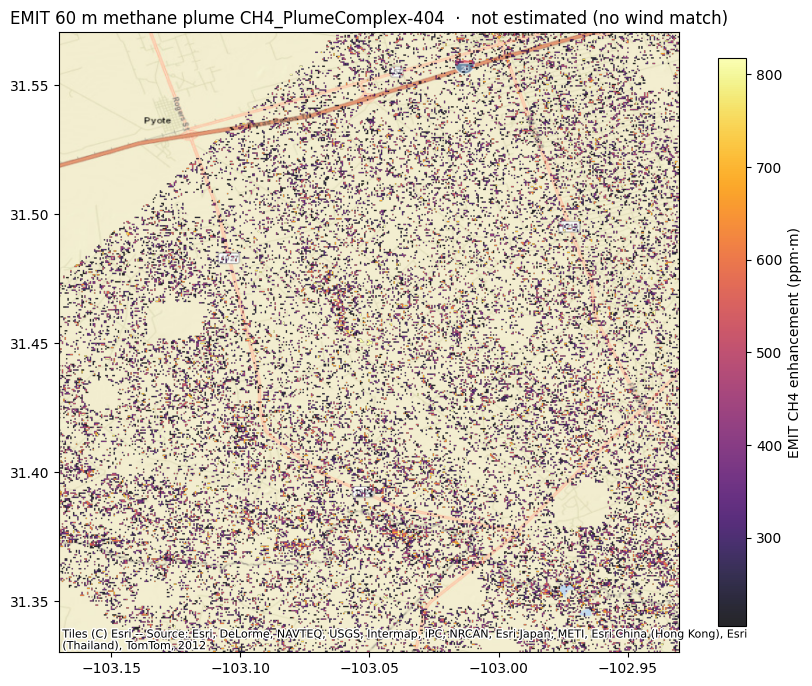

In [0]:
top = clipped.orderBy(F.col("max_conc_ppmm").desc()).first()
lon, lat = top["lon_max"], top["lat_max"]
pad = 0.12  # ~12 km window for regional context around the plume
_rate = top["emission_rate_kg_hr"]
_rate_txt = f"{_rate:,.0f} kg/hr" if _rate is not None else "not estimated (no wind match)"
# vizx.plot_tile drapes the enhancement SCENE (EPSG:4326) over an Esri basemap,
# windowed to the plume and masked below 200 ppm·m so near-zero background drops
# out and the plume glows in place. Same helper standardizes NB02's raster view.
show_tile(
    top["scene"],
    band=1,
    window_bounds=(lon - pad, lat - pad, lon + pad, lat + pad),
    mask_below=200,  # ppm·m — isolate the plume from near-zero background
    stretch=(2, 99),
    colorbar_label="EMIT CH4 enhancement (ppm·m)",
    title=f"EMIT 60 m methane plume {top['plume_id']}  ·  {_rate_txt}",
)

## What we built

- **`emit_scenes`** (Delta) — the staged EMIT enhancement COG + plume products (Volume paths).
- **`emit_plumes`** (Delta) — per-plume outline + JPL emission rate / max concentration / wind.
- **`plume_quant`** (Delta) — JPL emission rate alongside GeoBrix's clipped-raster enhancement.
- A **quantified high-resolution EMIT plume** with an emission rate in kg/hr.

GeoBrix: `EmitDownloader` (`EarthdataClient`), `raster_gbx`, `geojson_gbx`, `rst_clip`, `rst_summary`.

Next: **notebook 04** attributes the plume to the nearest well pad (TX RRC).